In [1]:

import pandas as pd

# Load the forecast dataset
df = pd.read_csv("../data/abuja_forecast_training.csv")

# 1. Dataset dimensions
print("DATASET SHAPE")
print(df.shape)

# 2. Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Duplicate dates
print("\nDUPLICATE DATES")
print(df["time"].duplicated().sum())

# 4. Date coverage
df["time"] = pd.to_datetime(df["time"])

print("\nDATE COVERAGE")
print("Start:", df["time"].min())
print("End:", df["time"].max())

# 5. Verify actual rainfall labels
actual_label_check = (
    df["actual_precipitation_sum"] > 0.1
).astype(int)

print("\nACTUAL RAINFALL LABEL CHECK")
print(
    "Mismatched labels:",
    (actual_label_check != df["rain"]).sum()
)

# 6. Verify forecast rainfall classifications
forecast_label_check = (
    df["forecast_precipitation_sum"] > 0.1
).astype(int)

print("\nFORECAST RAINFALL LABEL CHECK")
print(
    "Mismatched classifications:",
    (forecast_label_check != df["forecast_rain"]).sum()
)

# 7. Actual rainfall class distribution by year
print("\nACTUAL RAINFALL BY YEAR")
df["year"] = df["time"].dt.year

print(
    pd.crosstab(
        df["year"],
        df["rain"],
        margins=True
    )
)

# 8. Actual rainfall class distribution by month
print("\nACTUAL RAINFALL BY MONTH")
df["month"] = df["time"].dt.month

print(
    pd.crosstab(
        df["month"],
        df["rain"],
        normalize="index"
    ).round(3)
)


DATASET SHAPE
(712, 11)

MISSING VALUES
time                          0
temperature_max               0
temperature_min               0
temperature_mean              0
humidity_mean                 0
forecast_precipitation_sum    0
wind_speed_max                0
cloud_cover_mean              0
actual_precipitation_sum      0
rain                          0
forecast_rain                 0
dtype: int64

DUPLICATE DATES
0

DATE COVERAGE
Start: 2024-01-20 00:00:00
End: 2025-12-31 00:00:00

ACTUAL RAINFALL LABEL CHECK
Mismatched labels: 0

FORECAST RAINFALL LABEL CHECK
Mismatched classifications: 0

ACTUAL RAINFALL BY YEAR
rain    0    1  All
year               
2024  191  156  347
2025  196  169  365
All   387  325  712

ACTUAL RAINFALL BY MONTH
rain       0      1
month              
1      1.000  0.000
2      0.982  0.018
3      0.887  0.113
4      0.683  0.317
5      0.532  0.468
6      0.250  0.750
7      0.000  1.000
8      0.016  0.984
9      0.017  0.983
10     0.355  0.645
11     

In [2]:
actual_check = (
    df["actual_precipitation_sum"] > 0.1
).astype(int)

forecast_check = (
    df["forecast_precipitation_sum"] > 0.1
).astype(int)

print("Actual label mismatches:",
      (actual_check != df["rain"]).sum())

print("Forecast label mismatches:",
      (forecast_check != df["forecast_rain"]).sum())

print("\nActual rainfall counts:")
print(df["rain"].value_counts().sort_index())

print("\nForecast baseline counts:")
print(df["forecast_rain"].value_counts().sort_index())

Actual label mismatches: 0
Forecast label mismatches: 0

Actual rainfall counts:
rain
0    387
1    325
Name: count, dtype: int64

Forecast baseline counts:
forecast_rain
0    292
1    420
Name: count, dtype: int64


In [4]:

# Select input features
X = df[[
    "temperature_max",
    "temperature_min",
    "temperature_mean",
    "humidity_mean",
    "forecast_precipitation_sum",
    "wind_speed_max",
    "cloud_cover_mean"
]]

# Select target variable
y = df["rain"]

# Split chronologically (80% training, 20% testing)
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (569, 7)
X_test: (143, 7)
y_train: (569,)
y_test: (143,)


In [5]:
from sklearn.linear_model import LogisticRegression

In [6]:
model = LogisticRegression(max_iter=1000)

In [8]:
model.fit(X_train, y_train)



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [9]:
# Make predictions on the test data
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [10]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))

   Actual  Predicted
0       1          1
1       1          1
2       1          1
3       1          1
4       1          1
5       1          1
6       1          1
7       1          1
8       1          1
9       1          1


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 91.61 %


In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[62  8]
 [ 4 69]]


In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Rain", "Rain"]
))

              precision    recall  f1-score   support

     No Rain       0.94      0.89      0.91        70
        Rain       0.90      0.95      0.92        73

    accuracy                           0.92       143
   macro avg       0.92      0.92      0.92       143
weighted avg       0.92      0.92      0.92       143



In [14]:
from sklearn.metrics import accuracy_score, classification_report

# Get the original forecast classifications for the test period
baseline_pred = df["forecast_rain"].iloc[split_index:]

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Original Forecast Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

print("\nOriginal Forecast Classification Report:")
print(classification_report(
    y_test,
    baseline_pred,
    target_names=["No Rain", "Rain"]
))

print("\nLogistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Original Forecast Accuracy: 94.41 %

Original Forecast Classification Report:
              precision    recall  f1-score   support

     No Rain       0.94      0.94      0.94        70
        Rain       0.95      0.95      0.95        73

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143


Logistic Regression Accuracy: 91.61 %


In [15]:
from sklearn.metrics import confusion_matrix

# Original forecast confusion matrix
baseline_cm = confusion_matrix(y_test, baseline_pred)

print("Original Forecast Confusion Matrix:")
print(baseline_cm)

# Logistic Regression confusion matrix
model_cm = confusion_matrix(y_test, y_pred)

print("\nLogistic Regression Confusion Matrix:")
print(model_cm)

Original Forecast Confusion Matrix:
[[66  4]
 [ 4 69]]

Logistic Regression Confusion Matrix:
[[62  8]
 [ 4 69]]


In [17]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()


In [19]:
nb_model.fit(X_train, y_train)



,priors,None
,var_smoothing,1e-09


In [20]:
nb_pred = nb_model.predict(X_test)

print("Naive Bayes predictions completed!")

Naive Bayes predictions completed!


In [21]:
nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:",
      round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 93.01 %


In [22]:
from sklearn.metrics import confusion_matrix

nb_cm = confusion_matrix(y_test, nb_pred)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[68  2]
 [ 8 65]]


In [23]:
from sklearn.metrics import classification_report

print("Naive Bayes Classification Report:")
print(classification_report(
    y_test,
    nb_pred,
    target_names=["No Rain", "Rain"]
))

Naive Bayes Classification Report:
              precision    recall  f1-score   support

     No Rain       0.89      0.97      0.93        70
        Rain       0.97      0.89      0.93        73

    accuracy                           0.93       143
   macro avg       0.93      0.93      0.93       143
weighted avg       0.93      0.93      0.93       143



In [24]:
from sklearn.ensemble import RandomForestClassifier

In [25]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [26]:
rf_model.fit(X_train, y_train)



,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [28]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 93.71 %


In [29]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[67  3]
 [ 6 67]]


In [30]:
print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Rain", "Rain"]
))

Random Forest Classification Report:
              precision    recall  f1-score   support

     No Rain       0.92      0.96      0.94        70
        Rain       0.96      0.92      0.94        73

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143



In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = {
    "Original Forecast": baseline_pred,
    "Logistic Regression": y_pred,
    "Naive Bayes": nb_pred,
    "Random Forest": rf_pred
}

comparison_results = []

for name, predictions in results.items():

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score
  Original Forecast    0.9441     0.9452  0.9452    0.9452
Logistic Regression    0.9161     0.8961  0.9452    0.9200
        Naive Bayes    0.9301     0.9701  0.8904    0.9286
      Random Forest    0.9371     0.9571  0.9178    0.9371


In [32]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                      Feature  Importance
0             temperature_max    0.227078
3               humidity_mean    0.222056
4  forecast_precipitation_sum    0.160101
2            temperature_mean    0.144841
6            cloud_cover_mean    0.125826
1             temperature_min    0.077014
5              wind_speed_max    0.043084


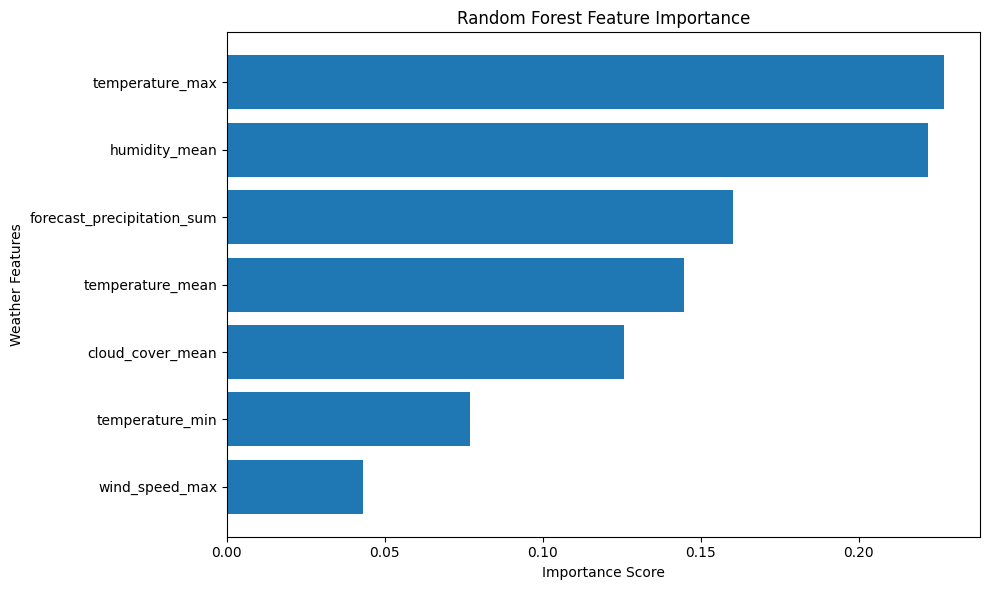

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Weather Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [34]:
# Create a validation split from the training data
validation_index = int(len(X_train) * 0.8)

X_train_new = X_train.iloc[:validation_index]
X_val = X_train.iloc[validation_index:]

y_train_new = y_train.iloc[:validation_index]
y_val = y_train.iloc[validation_index:]

print("New training records:", len(X_train_new))
print("Validation records:", len(X_val))

print("\nValidation period:")
print(df["time"].iloc[split_index - len(X_val):split_index].min())
print(df["time"].iloc[split_index - len(X_val):split_index].max())

New training records: 455
Validation records: 114

Validation period:
2025-04-19 00:00:00
2025-08-10 00:00:00


In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_model_new = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [36]:
rf_model_new.fit(X_train_new, y_train_new)

print("New Random Forest training completed!")

New Random Forest training completed!


In [37]:
rf_val_pred = rf_model_new.predict(X_val)

print("Validation predictions completed!")

Validation predictions completed!


In [38]:
from sklearn.metrics import accuracy_score

rf_val_accuracy = accuracy_score(y_val, rf_val_pred)

print("Random Forest Validation Accuracy:",
      round(rf_val_accuracy * 100, 2), "%")

Random Forest Validation Accuracy: 78.07 %


In [39]:
baseline_val_pred = df["forecast_rain"].iloc[
    split_index - len(X_val):split_index
]

baseline_val_accuracy = accuracy_score(
    y_val,
    baseline_val_pred
)

print("Original Forecast Validation Accuracy:",
      round(baseline_val_accuracy * 100, 2), "%")

Original Forecast Validation Accuracy: 82.46 %


In [40]:
from sklearn.metrics import confusion_matrix

print("Random Forest Validation Confusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred))

print("\nOriginal Forecast Validation Confusion Matrix:")
print(confusion_matrix(y_val, baseline_val_pred))

Random Forest Validation Confusion Matrix:
[[15 13]
 [12 74]]

Original Forecast Validation Confusion Matrix:
[[ 9 19]
 [ 1 85]]


In [41]:
from sklearn.metrics import classification_report

print("RANDOM FOREST:")
print(classification_report(
    y_val,
    rf_val_pred,
    target_names=["No Rain", "Rain"]
))

print("\nORIGINAL FORECAST:")
print(classification_report(
    y_val,
    baseline_val_pred,
    target_names=["No Rain", "Rain"]
))

RANDOM FOREST:
              precision    recall  f1-score   support

     No Rain       0.56      0.54      0.55        28
        Rain       0.85      0.86      0.86        86

    accuracy                           0.78       114
   macro avg       0.70      0.70      0.70       114
weighted avg       0.78      0.78      0.78       114


ORIGINAL FORECAST:
              precision    recall  f1-score   support

     No Rain       0.90      0.32      0.47        28
        Rain       0.82      0.99      0.89        86

    accuracy                           0.82       114
   macro avg       0.86      0.65      0.68       114
weighted avg       0.84      0.82      0.79       114



In [42]:
from sklearn.metrics import balanced_accuracy_score

rf_balanced = balanced_accuracy_score(
    y_val, rf_val_pred
)

baseline_balanced = balanced_accuracy_score(
    y_val, baseline_val_pred
)

print("Random Forest Balanced Accuracy:",
      round(rf_balanced * 100, 2), "%")

print("Original Forecast Balanced Accuracy:",
      round(baseline_balanced * 100, 2), "%")

Random Forest Balanced Accuracy: 69.81 %
Original Forecast Balanced Accuracy: 65.49 %


In [43]:
# Get the probability of rain (class 1)
rf_probabilities = rf_model_new.predict_proba(X_val)[:, 1]

# Display the first 10 probabilities
print(rf_probabilities[:10])

[0.29 0.   0.02 0.56 0.38 0.07 0.6  0.66 0.31 0.73]


In [44]:
from sklearn.metrics import balanced_accuracy_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    score = balanced_accuracy_score(
        y_val,
        predictions
    )

    print(
        "Threshold:", threshold,
        "| Balanced Accuracy:", round(score * 100, 2), "%"
    )

Threshold: 0.3 | Balanced Accuracy: 63.12 %
Threshold: 0.4 | Balanced Accuracy: 66.15 %
Threshold: 0.5 | Balanced Accuracy: 69.81 %
Threshold: 0.6 | Balanced Accuracy: 72.3 %
Threshold: 0.7 | Balanced Accuracy: 75.37 %


In [45]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Apply the 0.70 threshold
rf_val_pred_07 = (
    rf_probabilities >= 0.70
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred_07))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_pred_07,
    target_names=["No Rain", "Rain"]
))

Confusion Matrix:
[[23  5]
 [27 59]]

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.46      0.82      0.59        28
        Rain       0.92      0.69      0.79        86

    accuracy                           0.72       114
   macro avg       0.69      0.75      0.69       114
weighted avg       0.81      0.72      0.74       114



In [46]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.60, 0.65, 0.70, 0.75, 0.80]

for threshold in thresholds:
    predictions = (rf_probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_val, predictions), 4))
    print("Balanced Accuracy:", round(balanced_accuracy_score(y_val, predictions), 4))
    print("Rain Precision:", round(precision_score(y_val, predictions), 4))
    print("Rain Recall:", round(recall_score(y_val, predictions), 4))
    print("Rain F1:", round(f1_score(y_val, predictions), 4))


Threshold: 0.6
Accuracy: 0.7456
Balanced Accuracy: 0.723
Rain Precision: 0.88
Rain Recall: 0.7674
Rain F1: 0.8199

Threshold: 0.65
Accuracy: 0.7632
Balanced Accuracy: 0.7708
Rain Precision: 0.9155
Rain Recall: 0.7558
Rain F1: 0.828

Threshold: 0.7
Accuracy: 0.7193
Balanced Accuracy: 0.7537
Rain Precision: 0.9219
Rain Recall: 0.686
Rain F1: 0.7867

Threshold: 0.75
Accuracy: 0.7105
Balanced Accuracy: 0.76
Rain Precision: 0.9344
Rain Recall: 0.6628
Rain F1: 0.7755

Threshold: 0.8
Accuracy: 0.6842
Balanced Accuracy: 0.7546
Rain Precision: 0.9464
Rain Recall: 0.6163
Rain F1: 0.7465


In [47]:
# Train the final Random Forest model
from sklearn.ensemble import RandomForestClassifier

final_rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_rf_model.fit(X_train, y_train)

# Get rain probabilities for the test data
test_probabilities = final_rf_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_rf_predictions = (test_probabilities >= 0.65).astype(int)

# Evaluate the final model
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

print("Final Random Forest — Threshold 0.65")
print("Accuracy:", accuracy_score(y_test, final_rf_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, final_rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_rf_predictions,
    target_names=["No Rain", "Rain"]
))

Final Random Forest — Threshold 0.65
Accuracy: 0.9230769230769231
Balanced Accuracy: 0.9240704500978474

Confusion Matrix:
[[68  2]
 [ 9 64]]

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.88      0.97      0.93        70
        Rain       0.97      0.88      0.92        73

    accuracy                           0.92       143
   macro avg       0.93      0.92      0.92       143
weighted avg       0.93      0.92      0.92       143



In [48]:
import joblib
import os

# Create the models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
joblib.dump(
    final_rf_model,
    "../models/random_forest_model.pkl"
)

# Save the feature names and prediction threshold
model_info = {
    "features": features,
    "threshold": 0.65
}

joblib.dump(
    model_info,
    "../models/model_info.pkl"
)

print("Model and configuration saved successfully!")

Model and configuration saved successfully!
